#### Suppose we are given an input sequence - x^1 to x^t 
#### The input is a text (for example, a sentence like "Your journey starts with one step") that has already been converted into token embeddings of d=3 dimensions
#### For instance, x^1  = is a d-dimensional vector representing the word "Your", and so forth

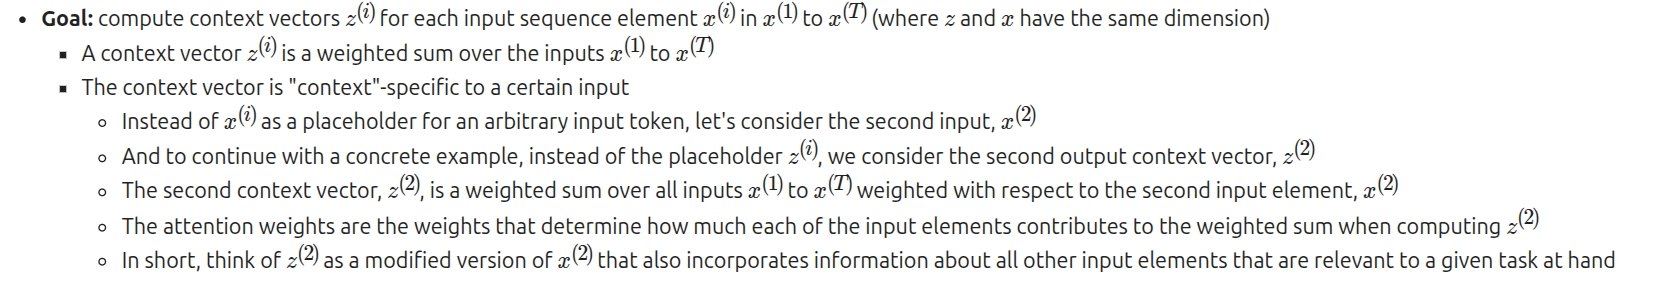

In [2]:
import torch

inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89],  # Your     (x^1)
        [0.55, 0.87, 0.66],  # journey  (x^2)
        [0.57, 0.85, 0.64],  # starts   (x^3)
        [0.22, 0.58, 0.33],  # with     (x^4)
        [0.77, 0.25, 0.10],  # one      (x^5)
        [0.05, 0.80, 0.55],  # step     (x^6)
    ]
)


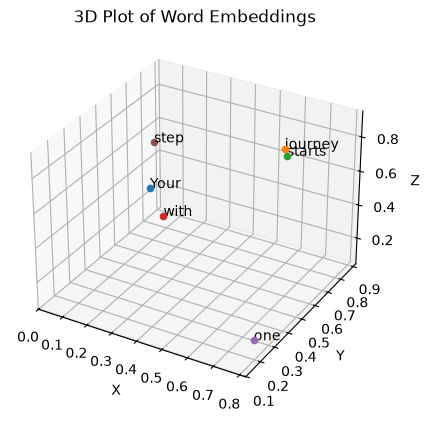

In [3]:
import matplotlib.pyplot as plt
# from mpl_toolkits.mplot3d import Axes3D

# Corresponding words
words = ["Your", "journey", "starts", "with", "one", "step"]

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.title("3D Plot of Word Embeddings")
plt.show()


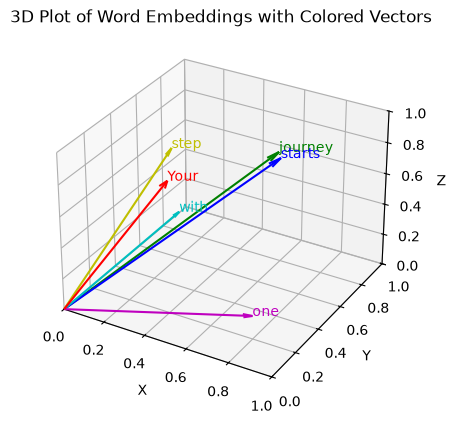

In [4]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

# Define a list of colors for the vectors
colors = ["r", "g", "b", "c", "m", "y"]

# Plot each vector with a different color and annotate with the corresponding word
for x, y, z, word, color in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title("3D Plot of Word Embeddings with Colored Vectors")
plt.show()


#### The second input token serves as the query
#### Goal - compute the unnormalized attention scores by computing the dot product between the query x2 and all other input tokens (x1 to xt):

In [ ]:
query_vec = inputs[1]

# Now we will calculate the attention scores for each word vector with respect to the query vector (inputs[1]) using dot product

# Attention scores - quantitfies the relevance of each word vector to the query vector , how important each word in the input sequence is to the query vector(current word in the sequence)

# It is calculated by taking the dot product of the query vector with each of the word vectors in the input sequence. The resulting scores indicate how much attention should be paid to each word when processing the query vector.

# Higher the value of dot product, higher the attention score, indicating that the corresponding word vector is more relevant to the query vector.

# as there are 6 inputs, we will have 6 attention scores, one for each word vector in the input sequence.

attention_scores = torch.empty(inputs.size(0))

print("Query vector [Second word of the sequence] : ", query_vec)
print("Dimensions of query vector :", query_vec.size())
print("Dimension of attention scores :", attention_scores.size())

for i in range(inputs.size(0)):
    attention_scores[i] = torch.dot(query_vec, inputs[i])
    # dot product (transpose not necessary here since they are 1-dim vectors)

print("Attention scores:", attention_scores)


Query vector [Second word of the sequence] :  tensor([0.5500, 0.8700, 0.6600])
Dimensions of query vector : torch.Size([3])
Dimension of attention scores : torch.Size([6])
Attention scores: tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


### Normalization of Attention Scores:
#### The main goal behind the normalization is to obtain attention weights that sum up to 1.
#### This normalization is a convention that is useful for interpretation and for maintaining training stability in an LLM.
#### We use softmax function for normalization.
#### This approach is better at managing extreme values and offers more favorable gradient properties during training.

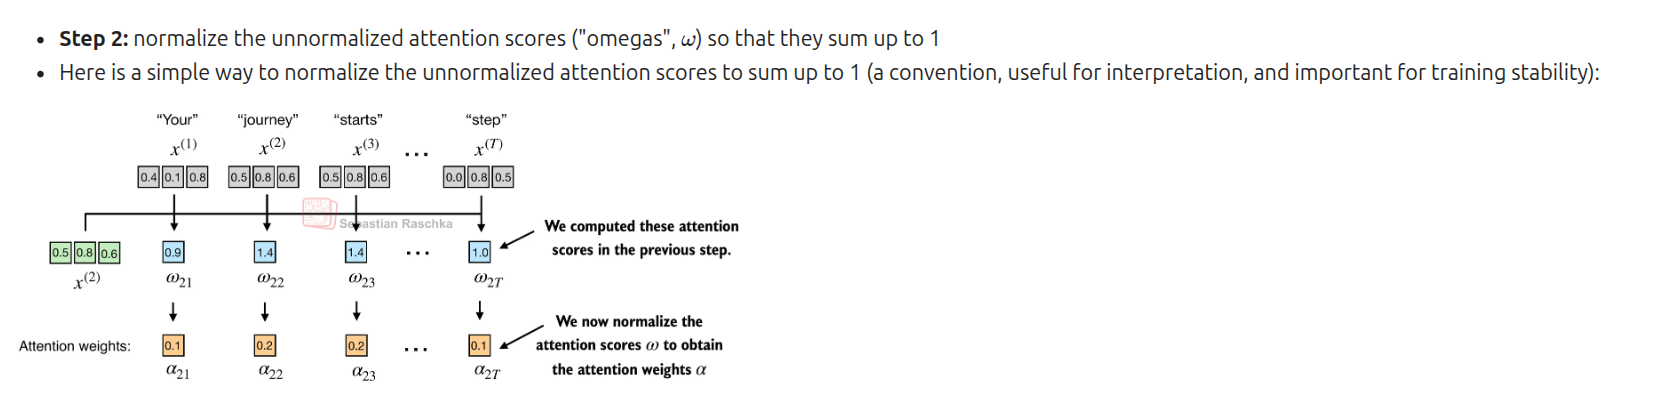

In [7]:
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)
    # dim = 0 means we are applying softmax across the first dimension (rows) of the input tensor x. In this case, x is a 1D tensor (vector) of attention scores, so dim=0 indicates that we want to compute the softmax over all the elements in that vector.

attn_weights_naive = softmax_naive(attention_scores)
print("Attention weights (naive softmax) : ", attn_weights_naive)
print("Sun of attention weights (naive softmax) : ", attn_weights_naive.sum())  # should be 1.0


Attention weights (naive softmax) :  tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sun of attention weights (naive softmax) :  tensor(1.)


#### The naive implementation above can suffer from numerical instability issues for large or small input values due to overflow and underflow issues
#### Hence, in practice, it's recommended to use the PyTorch implementation of softmax instead, which has been highly optimized for performance:

In [ ]:
attn_weights_normalized = torch.softmax(attention_scores, dim=0)

print("Attention weights (torch.softmax) : ", attn_weights_normalized)
print(
    "Sum of attention weights (torch.softmax) : ", attn_weights_normalized.sum()
)  # should be 1.0


Attention weights (torch.softmax) :  tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
Sum of attention weights (torch.softmax) :  tensor(1.)


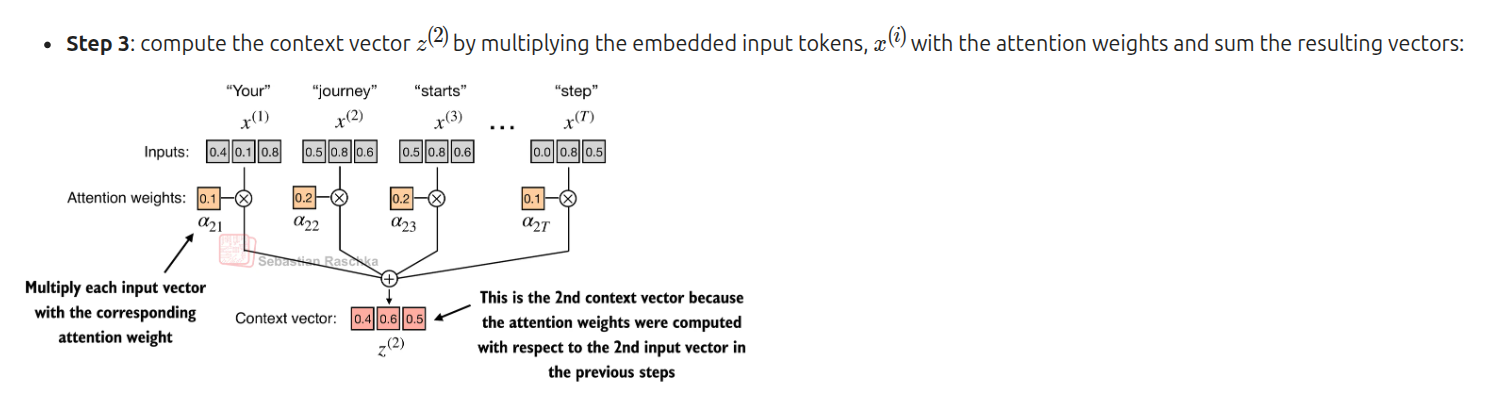

In [ ]:
query_vec = inputs[1]

context_vec_2 = torch.zeros(inputs.size(1))  # initialize context vector with zeros

for i,x_i in enumerate(inputs):
    context_vec_2 += attn_weights_normalized[i] * x_i

print("Context vector for the query vector [Second word of the sequence] : ", context_vec_2)


Context vector for the query vector [Second word of the sequence] :  tensor([0.4419, 0.6515, 0.5683])


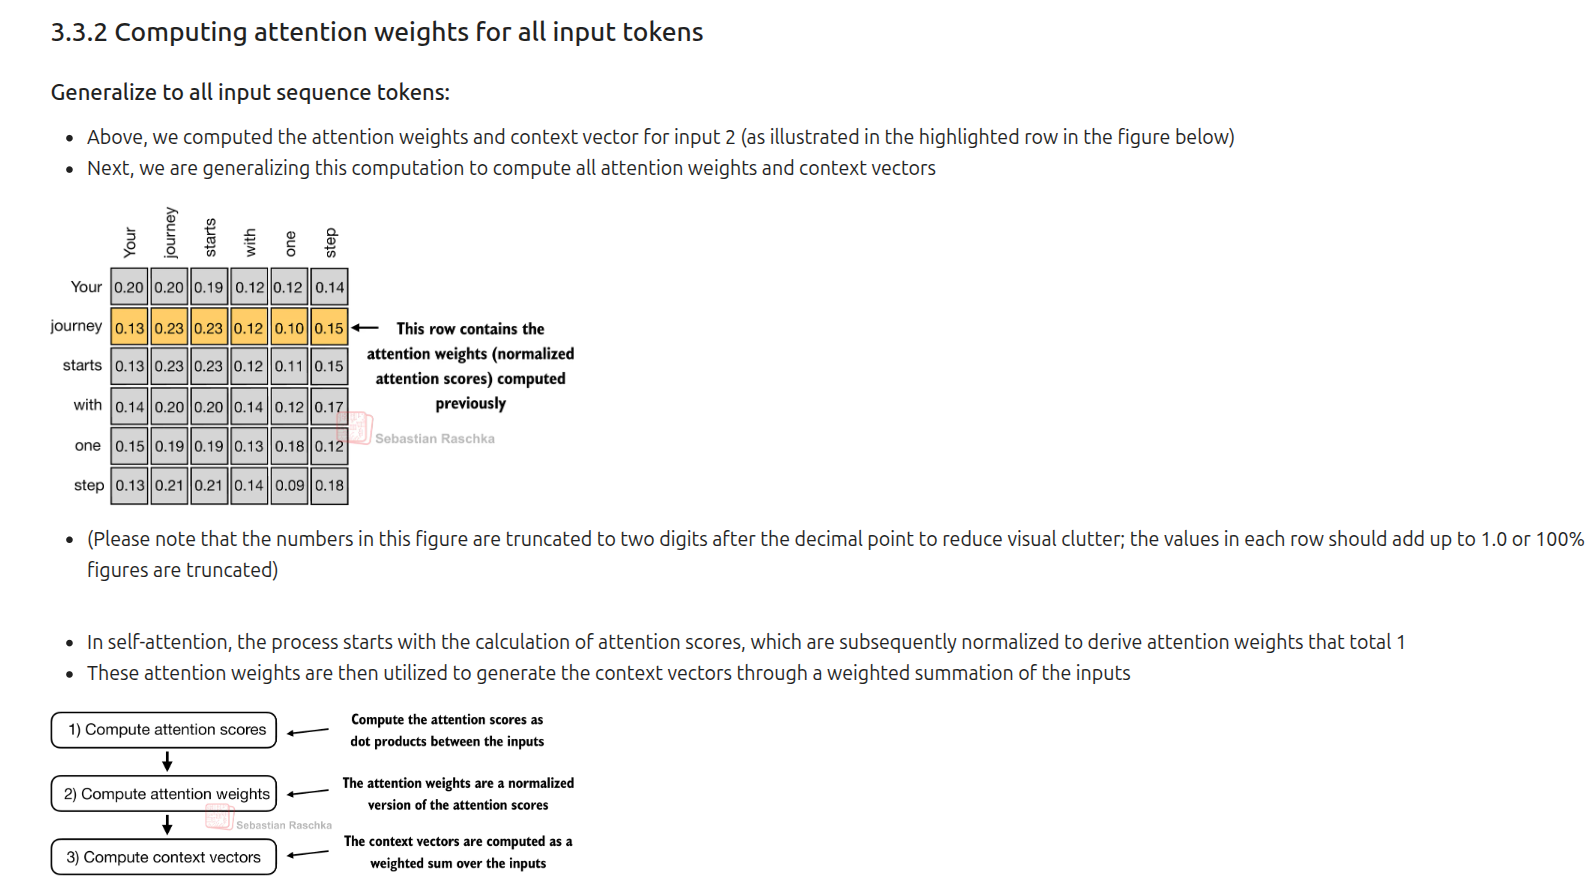

In [ ]:
# Step 1 : Compute the attention scores between all pairs of word vectors in the input sequence using matrix multiplication. This will give us a un-normalized attention score matrix, where each entry (i, j) represents the attention score between the i-th and j-th word vectors. Basically how much attention should be paid to the j-th word vector when processing the i-th word vector.

attention_scores = inputs @ inputs.T
print("Attention scores (matrix multiplication) : ", attention_scores)


Attention scores (matrix multiplication) :  tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])


In [ ]:
# Step 2 - Normalize the attention scores using the softmax function along the last dimension (dim=-1) to obtain the attention weights. This will ensure that the attention weights for each word vector sum to 1, allowing us to interpret them as probabilities.
attn_weights = torch.softmax(attention_scores, dim=-1)
print("Attention weights (matrix multiplication) : ", attn_weights)


Attention weights (matrix multiplication) :  tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])


<div class="alert alert-block alert-warning">

In the context of using PyTorch, the dim parameter in functions like torch.softmax specifies
the dimension of the input tensor along which the function will be computed. 

By setting
dim=-1, we are instructing the softmax function to apply the normalization along the last
dimension of the attn_scores tensor. 

If attn_scores is a 2D tensor (for example, with a
shape of [rows, columns]), dim = -1 : will normalize across the columns so that the values in
each row (summing over the column dimension) sum up to 1.
    
</div>

In [14]:
row_2_sum = sum([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])
print("Row 2 sum :", row_2_sum)

print("All row sums :", attn_weights.sum(dim=-1))


Row 2 sum : 1.0
All row sums : tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


<div class="alert alert-block alert-success">

In the third and last step, we now use these attention weights to compute all context
vectors via matrix multiplication:

</div>

In [15]:
#  Step 3 - Compute the context vectors for each word vector by taking the weighted sum of all word vectors in the input sequence, using the attention weights as coefficients. This will give us a new set of context vectors that capture the relevant information from the entire input sequence for each word vector.
context_vectors = attn_weights @ inputs 

# (6*6) @ (6*3) = (6*3)  => 6 context vectors, each of dimension 3
print("Context vectors (matrix multiplication) : ", context_vectors)


Context vectors (matrix multiplication) :  tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


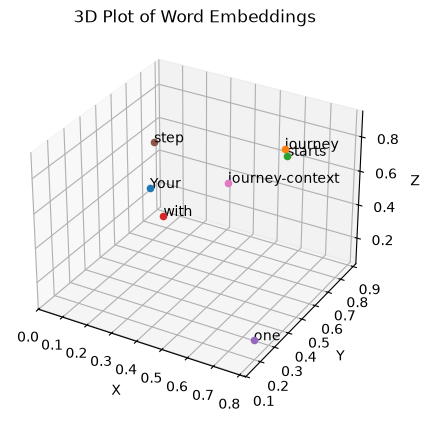

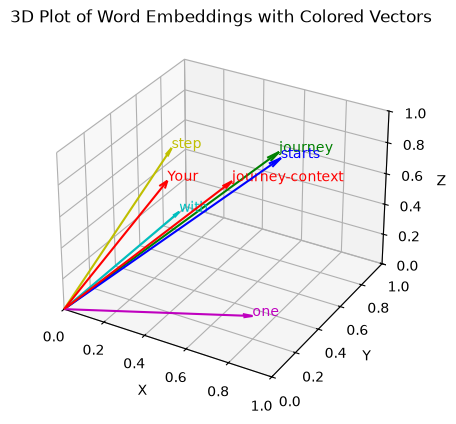

In [ ]:
import matplotlib.pyplot as plt
# from mpl_toolkits.mplot3d import Axes3D

inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89],  # Your     (x^1)
        [0.55, 0.87, 0.66],  # journey  (x^2)
        [0.57, 0.85, 0.64],  # starts   (x^3)
        [0.22, 0.58, 0.33],  # with     (x^4)
        [0.77, 0.25, 0.10],  # one      (x^5)
        [0.05, 0.80, 0.55],  # step     (x^6)
        [0.4419, 0.6515, 0.5683],
    ]
)

# Corresponding words
words = ["Your", "journey", "starts", "with", "one", "step", "journey-context"]

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

plt.title("3D Plot of Word Embeddings")
plt.show()

# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

# Define a list of colors for the vectors
colors = ["r", "g", "b", "c", "m", "y", "r"]

# Plot each vector with a different color and annotate with the corresponding word
for x, y, z, word, color in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title("3D Plot of Word Embeddings with Colored Vectors")
plt.show()


In [17]:
import tiktoken

# Initialize the encodings for GPT-2, GPT-3, and GPT-4
encodings = {
    "gpt2": tiktoken.get_encoding("gpt2"),
    "gpt3": tiktoken.get_encoding("p50k_base"),  # Commonly associated with GPT-3 models
    "gpt4": tiktoken.get_encoding("cl100k_base"),  # Used for GPT-4 and later versions
}

# Get the vocabulary size for each encoding
vocab_sizes = {model: encoding.n_vocab for model, encoding in encodings.items()}

# Print the vocabulary sizes
for model, size in vocab_sizes.items():
    print(f"The vocabulary size for {model.upper()} is: {size}")


The vocabulary size for GPT2 is: 50257
The vocabulary size for GPT3 is: 50281
The vocabulary size for GPT4 is: 100277
